# 08 — Final evaluation on the 2022+ holdout

*CRISP-DM phase 6 · code: `run_holdout.py`*

The one-time test on data never used for any decision. The setup (features, models, horizons, labels) was fixed before it was first run on 2026-10-27. Re-running this notebook reproduces that test with the same fixed setup; **no decision may be changed based on it**.

← previous: [`07_interpretation.ipynb`](07_interpretation.ipynb) · next: [`09_candlestick_patterns.ipynb`](09_candlestick_patterns.ipynb) →

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path[:0] = [str(ROOT / "src"), str(ROOT)]   # project package + root scripts

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "font.size": 10})

In [2]:
def run_script(module, *args):
    """Run a project script's main() exactly as on the command line, then restore inline plots."""
    import importlib
    mod = importlib.import_module(module)
    old = sys.argv
    sys.argv = [f"{module}.py", *args]
    try:
        code = mod.main()
    finally:
        sys.argv = old
    get_ipython().run_line_magic("matplotlib", "inline")
    return code

In [3]:
run_script("run_holdout")

[18:27:26] ONE-TIME HOLDOUT: features=main (13), train from 1962-01-01, test 2022 -> 2026-10-23, yearly refit, gap 21


Model is not converging.  Current: 49182.81719900228 is not greater than 49182.85411121424. Delta is -0.036912211959133856


[18:27:29]       fold 1/5: test 2022 (train 14,780 rows up to 2021-12-31)


Model is not converging.  Current: 49866.18821946934 is not greater than 49866.223009602036. Delta is -0.03479013269679854


[18:27:33]       fold 2/5: test 2023 (train 15,031 rows up to 2022-12-30)


Model is not converging.  Current: 50685.11406259953 is not greater than 50685.147178847204. Delta is -0.033116247672296595


... (5 outputs left out)

[18:27:43] Done in 18s; 57,936 predictions


[18:27:57] wrote reports/holdout_results.md/.csv and docs/figures/holdout_timeline.png



pr_auc (holdout):
label         bear        bear_merged        stressed        stressed_fixed       
horizon         5      21          5      21       5      21             5      21
method                                                                            
persistence  0.181  0.156       0.181  0.156    0.780  0.384          0.700  0.244
ma200_rule   0.465  0.413       0.465  0.413      NaN    NaN            NaN    NaN
hmm          0.464  0.359       0.464  0.359    0.687  0.485          0.552  0.375
logreg       0.481  0.433       0.484  0.441    0.938  0.549          0.855  0.437
lightgbm     0.448  0.345       0.423  0.346    0.947  0.590          0.903  0.359
svm          0.612  0.534       0.560  0.479    0.954  0.602          0.740  0.192

onset_pr_auc (holdout):
label       stressed        stressed_fixed       
horizon           5      21             5      21
method                                           
persistence    0.024  0.082          0.020  0.068
ma200_rul

0

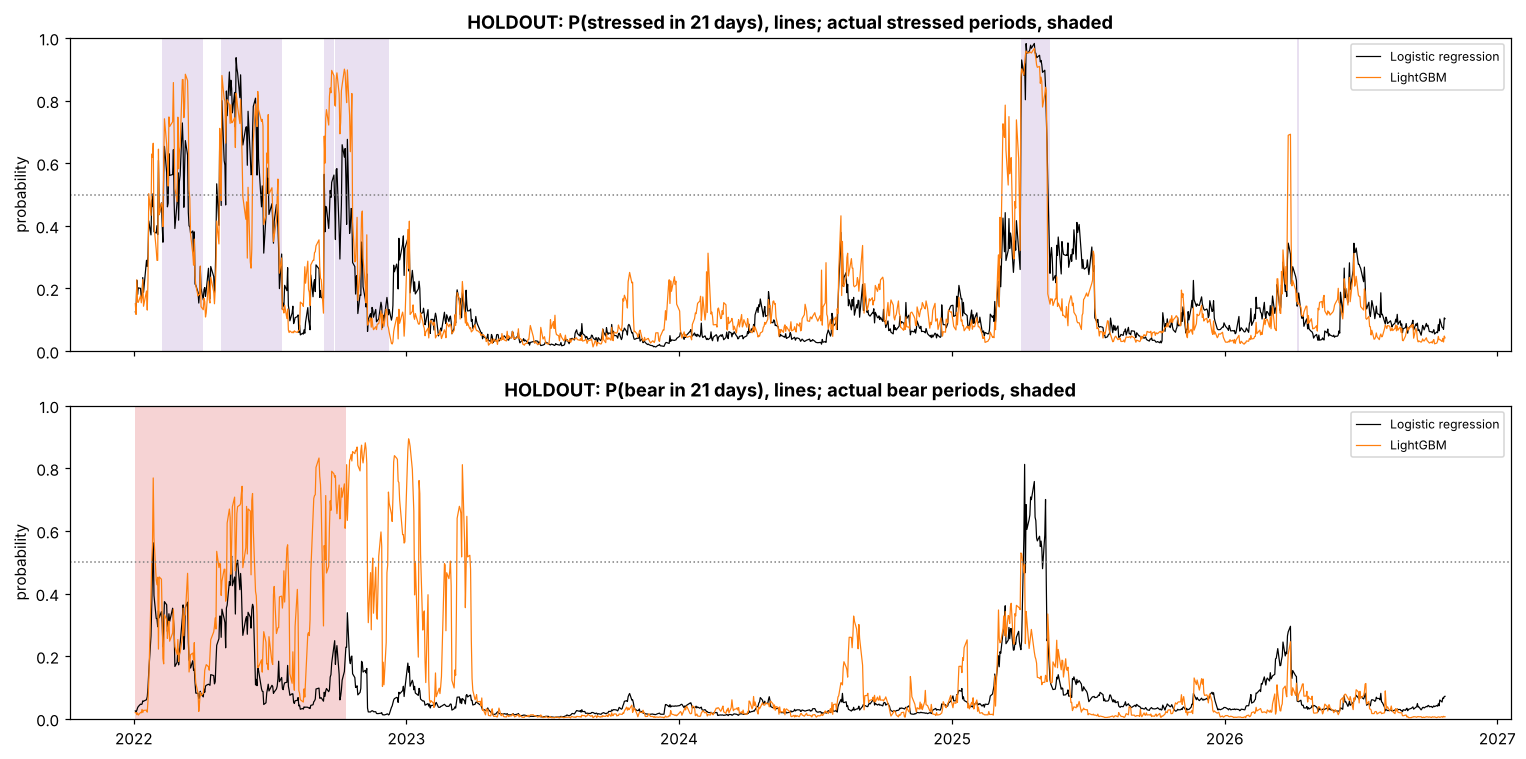

In [4]:
display(Image(ROOT / "docs" / "figures" / "holdout_timeline.png"))

In [5]:
display(Markdown((ROOT / "reports" / "holdout_results.md").read_text().replace("../docs/figures/", str(ROOT / "docs" / "figures") + "/")))

# Final holdout results (one-time test)

Generated 2026-11-25 18:27 by `run_holdout.py`. Test period **2022-01-01 → 2026-10-16** (last day whose target is already known). Models refit each January on all data from 1962, 21-day gap. Setup identical to validation; nothing was tuned on this period.

## `bear` in 5 days

Holdout base rate 15.9% (1,202 days).

| Method | PR-AUC (holdout) | PR-AUC (validation 1980–2021) | Onset PR-AUC (holdout) | Brier (holdout) |
|---|---|---|---|---|
| Baseline: no change | 0.181 | 0.131 | – | 0.340 |
| Baseline: price < 200-day MA | 0.465 | 0.299 | – | 0.142 |
| Baseline: 2-state HMM | 0.464 | 0.277 | – | 0.116 |
| Logistic regression | 0.481 | 0.361 | – | 0.117 |
| LightGBM | 0.448 | 0.358 | – | 0.110 |
| SVM (RBF) | **0.612** | 0.355 | – | 0.099 |

## `bear` in 21 days

Holdout base rate 14.8% (1,186 days).

| Method | PR-AUC (holdout) | PR-AUC (validation 1980–2021) | Onset PR-AUC (holdout) | Brier (holdout) |
|---|---|---|---|---|
| Baseline: no change | 0.156 | 0.122 | – | 0.358 |
| Baseline: price < 200-day MA | 0.413 | 0.261 | – | 0.158 |
| Baseline: 2-state HMM | 0.359 | 0.280 | – | 0.109 |
| Logistic regression | 0.433 | 0.293 | – | 0.112 |
| LightGBM | 0.345 | 0.340 | – | 0.119 |
| SVM (RBF) | **0.534** | 0.313 | – | 0.097 |

## `stressed` in 5 days

Holdout base rate 15.6% (1,202 days).

| Method | PR-AUC (holdout) | PR-AUC (validation 1980–2021) | Onset PR-AUC (holdout) | Brier (holdout) |
|---|---|---|---|---|
| Baseline: no change | 0.780 | 0.776 | 0.024 | 0.040 |
| Baseline: 2-state HMM | 0.687 | 0.749 | 0.165 | 0.091 |
| Logistic regression | 0.938 | 0.930 | 0.611 | 0.027 |
| LightGBM | 0.947 | 0.927 | 0.434 | 0.027 |
| SVM (RBF) | **0.954** | 0.847 | 0.518 | 0.038 |

## `stressed` in 21 days

Holdout base rate 15.8% (1,186 days).

| Method | PR-AUC (holdout) | PR-AUC (validation 1980–2021) | Onset PR-AUC (holdout) | Brier (holdout) |
|---|---|---|---|---|
| Baseline: no change | 0.384 | 0.512 | 0.082 | 0.138 |
| Baseline: 2-state HMM | 0.485 | 0.531 | 0.300 | 0.104 |
| Logistic regression | 0.549 | 0.661 | 0.516 | 0.094 |
| LightGBM | 0.590 | 0.648 | 0.622 | 0.084 |
| SVM (RBF) | **0.602** | 0.555 | 0.486 | 0.095 |

## `bear_merged` in 5 days

Holdout base rate 15.9% (1,202 days).

| Method | PR-AUC (holdout) | PR-AUC (validation 1980–2021) | Onset PR-AUC (holdout) | Brier (holdout) |
|---|---|---|---|---|
| Baseline: no change | 0.181 | 0.164 | – | 0.340 |
| Baseline: price < 200-day MA | 0.465 | 0.350 | – | 0.142 |
| Baseline: 2-state HMM | 0.464 | 0.313 | – | 0.116 |
| Logistic regression | 0.484 | 0.395 | – | 0.110 |
| LightGBM | 0.423 | 0.363 | – | 0.116 |
| SVM (RBF) | **0.560** | 0.362 | – | 0.097 |

## `bear_merged` in 21 days

Holdout base rate 14.8% (1,186 days).

| Method | PR-AUC (holdout) | PR-AUC (validation 1980–2021) | Onset PR-AUC (holdout) | Brier (holdout) |
|---|---|---|---|---|
| Baseline: no change | 0.156 | 0.152 | – | 0.358 |
| Baseline: price < 200-day MA | 0.413 | 0.312 | – | 0.158 |
| Baseline: 2-state HMM | 0.359 | 0.309 | – | 0.109 |
| Logistic regression | 0.441 | 0.338 | – | 0.107 |
| LightGBM | 0.346 | 0.335 | – | 0.124 |
| SVM (RBF) | **0.479** | 0.320 | – | 0.096 |

## `stressed_fixed` in 5 days

Holdout base rate 10.5% (1,202 days).

| Method | PR-AUC (holdout) | PR-AUC (validation 1980–2021) | Onset PR-AUC (holdout) | Brier (holdout) |
|---|---|---|---|---|
| Baseline: no change | 0.700 | 0.724 | 0.020 | 0.037 |
| Baseline: 2-state HMM | 0.552 | 0.426 | 0.146 | 0.110 |
| Logistic regression | 0.855 | 0.864 | 0.360 | 0.029 |
| LightGBM | **0.903** | 0.897 | 0.459 | 0.030 |
| SVM (RBF) | 0.740 | 0.812 | 0.091 | 0.050 |

## `stressed_fixed` in 21 days

Holdout base rate 10.6% (1,186 days).

| Method | PR-AUC (holdout) | PR-AUC (validation 1980–2021) | Onset PR-AUC (holdout) | Brier (holdout) |
|---|---|---|---|---|
| Baseline: no change | 0.244 | 0.315 | 0.068 | 0.121 |
| Baseline: 2-state HMM | 0.375 | 0.264 | 0.293 | 0.091 |
| Logistic regression | **0.437** | 0.563 | 0.566 | 0.078 |
| LightGBM | 0.359 | 0.487 | 0.342 | 0.085 |
| SVM (RBF) | 0.192 | 0.415 | 0.146 | 0.094 |

## Is the improvement over the baselines real? (block bootstrap)

95% confidence interval for PR-AUC(model) − PR-AUC(best baseline), resampling 63-day blocks (1,000 repetitions). If the interval stays above 0, the model is better than the baseline in the holdout.

| Target | Model | Best baseline | Difference | 95% CI |
|---|---|---|---|---|
| `stressed` 5d | Logistic regression | Baseline: no change | +0.158 | +0.097 to +0.281 |
| `stressed` 5d | LightGBM | Baseline: no change | +0.167 | +0.107 to +0.283 |
| `stressed` 21d | Logistic regression | Baseline: 2-state HMM | +0.064 | -0.136 to +0.350 |
| `stressed` 21d | LightGBM | Baseline: 2-state HMM | +0.105 | -0.056 to +0.343 |
| `bear` 5d | Logistic regression | Baseline: price < 200-day MA | +0.016 | -0.222 to +0.322 |
| `bear` 5d | LightGBM | Baseline: price < 200-day MA | -0.018 | -0.130 to +0.172 |
| `bear` 21d | Logistic regression | Baseline: price < 200-day MA | +0.020 | -0.261 to +0.378 |
| `bear` 21d | LightGBM | Baseline: price < 200-day MA | -0.068 | -0.188 to +0.172 |

## Stress episodes in the holdout (lasting ≥ 10 trading days)

Signal start relative to the first stressed day (21-day predictions): negative = warned in advance.

| Stress start | Days | HMM | Logistic | LightGBM |
|---|---|---|---|---|
| 2022-02-08 | 39 | +12 | +2 | +2 |
| 2022-04-28 | 55 | +0 | +1 | +1 |
| 2022-09-13 | 10 | +0 | +0 | +0 |
| 2022-09-28 | 52 | +1 | +1 | -11 |
| 2025-04-03 | 27 | +0 | +0 | +0 |

## Bear markets in the holdout

Bear market 2022-01-03 → 2022-10-12 (-25%). First ≥ 50% "bear within 21 days" signal:

| Method | Signal date | Days after peak | Market fall at signal |
|---|---|---|---|
| Baseline: price < 200-day MA | 2022-01-21 | 13 | -8% |
| Baseline: 2-state HMM | 2022-02-03 | 22 | -7% |
| Logistic regression | 2022-01-27 | 17 | -10% |
| LightGBM | 2022-01-25 | 15 | -9% |

![Holdout timeline](/home/claude/repo/sp500-regime-prediction/docs/figures/holdout_timeline.png)



**Result.** Short-term stress prediction holds out of sample (PR-AUC 0.94–0.95 vs. 0.78 for the best baseline); bear-market starts remain unpredictable.

The next notebooks extend the project from *regimes* to the **minimum and maximum price** (professor's request).